# 05c · Finer communities on the cart/purchase graph, and a readable sub-graph
`05b` showed that Louvain on the full graph (views included) produces a handful of giant communities that mostly separate product categories (top 10 communities hold 99.7% of users, best enrichment of K-Means-flagged users only 1.47x). Views are 94% of all edges and carry little intent.

Here community detection is repeated on **cart + purchase edges only**, with **Leiden** at a higher resolution (`gamma`), and enrichment is tested for statistical significance (hypergeometric test). The notebook ends with a drawable sub-graph of flagged fan-out users (LO 6). Metrics: `ml/outputs/05c_metrics.json`.

In [1]:
import os, json, time
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import hypergeom
from neo4j import GraphDatabase

URI, USER, PWD = os.environ["NEO4J_URI"], os.environ["NEO4J_USER"], os.environ["NEO4J_PASSWORD"]
OUT, FIG = "/home/jovyan/work/ml/outputs", "/home/jovyan/work/laporan/gambar"
driver = GraphDatabase.driver(URI, auth=(USER, PWD))
metrics = {}
def q(query, **p):
    with driver.session(database="neo4j") as s: return s.run(query, **p).data()
def save(): json.dump(metrics, open(f"{OUT}/05c_metrics.json", "w"), indent=2, default=str)

## 1. Cart + purchase projection (all products, undirected, weighted by count)

In [2]:
q("CALL gds.graph.drop('cp', false)")
t0 = time.time()
proj = q("""MATCH (u:User)-[r:INTERACTED]->(p:Product) WHERE r.type IN ['cart','purchase']
    WITH u, p, sum(r.count) AS c
    RETURN gds.graph.project('cp', u, p, {sourceNodeLabels: labels(u), targetNodeLabels: labels(p), relationshipProperties: {count: c}},
                             {undirectedRelationshipTypes: ['*']}) AS g""")[0]["g"]
metrics["cp_projection"] = dict(nodeCount=proj["nodeCount"], relationshipCount=proj["relationshipCount"], seconds=round(time.time()-t0, 1))
print(metrics["cp_projection"]); save()

Received notification from DBMS server: <GqlStatusObject gql_status='01N03', status_description='warn: procedure field deprecated. The field `schema` of procedure gds.graph.drop() is deprecated.', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 0, 'line': 1, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "CALL gds.graph.drop('cp', false)"


{'nodeCount': 1277790, 'relationshipCount': 4961800, 'seconds': 53.9}


## 2. Leiden communities
`gamma` > 1 favours smaller communities. Several values are tried; the community count, modularity and size spread are compared before choosing one.

In [3]:
rows = []
for gamma in [1.0, 5.0, 20.0]:
    t0 = time.time()
    r = q("""CALL gds.leiden.mutate('cp', {mutateProperty:$p, gamma:$g, maxLevels:10, randomSeed:42, concurrency:4})
        YIELD communityCount, modularity, ranLevels RETURN *""", p=f"c_g{int(gamma)}", g=gamma)[0]
    r.update(gamma=gamma, seconds=round(time.time()-t0, 1)); rows.append(r); print(r)
metrics["leiden_gammas"] = rows; save()

{'communityCount': 7526, 'modularity': 0.6359856153341726, 'ranLevels': 7, 'gamma': 1.0, 'seconds': 1.9}


{'communityCount': 7749, 'modularity': 0.5735806278765354, 'ranLevels': 6, 'gamma': 5.0, 'seconds': 1.7}


{'communityCount': 8692, 'modularity': 0.5141264943738051, 'ranLevels': 6, 'gamma': 20.0, 'seconds': 1.7}


In [4]:
# pick gamma: the one giving the largest number of communities with >= 200 users and modularity >= 0.3
best = None
for r in rows:
    prop = f"c_g{int(r['gamma'])}"
    sizes = pd.DataFrame(q(f"CALL gds.graph.nodeProperty.stream('cp', '{prop}', ['User']) YIELD propertyValue RETURN propertyValue AS c, count(*) AS n")).sort_values("n", ascending=False)
    r["communities_ge_200_users"] = int((sizes.n >= 200).sum()); r["largest_share"] = float(sizes.n.max() / sizes.n.sum())
    print(r["gamma"], r["communities_ge_200_users"], round(r["largest_share"], 3), round(r["modularity"], 3))
ok = [r for r in rows if r["modularity"] >= 0.3]
GAMMA = max(ok, key=lambda r: r["communities_ge_200_users"])["gamma"] if ok else rows[0]["gamma"]
metrics["leiden_gammas"] = rows; metrics["gamma_selected"] = GAMMA; save(); print("selected gamma", GAMMA)

1.0 44 0.079 0.636


5.0 261 0.021 0.574


20.0 910 0.02 0.514
selected gamma 20.0


In [5]:
q("CALL gds.graph.nodeProperties.write('cp', [$p], ['User','Product']) YIELD propertiesWritten RETURN propertiesWritten", p=f"c_g{int(GAMMA)}")
q(f"MATCH (n) WHERE n.`c_g{int(GAMMA)}` IS NOT NULL SET n.leiden = n.`c_g{int(GAMMA)}` REMOVE n.`c_g{int(GAMMA)}`")
comm = pd.DataFrame(q("""MATCH (u:User) WHERE u.leiden IS NOT NULL
    RETURN u.leiden AS community, count(*) AS users, sum(CASE WHEN u.flagged THEN 1 ELSE 0 END) AS flagged""")).set_index("community")
N, K = int(comm.users.sum()), int(comm.flagged.sum())
comm["flag_rate"] = comm.flagged / comm.users
comm["lift"] = comm.flag_rate / (K / N)
comm["p_value"] = [hypergeom.sf(f - 1, N, K, n) for f, n in zip(comm.flagged, comm.users)]
metrics["leiden_summary"] = dict(users_in_graph=N, flagged_in_graph=K, communities=len(comm), ge_200=int((comm.users >= 200).sum()))
print(metrics["leiden_summary"]); save()

{'users_in_graph': 1185261, 'flagged_in_graph': 96720, 'communities': 8692, 'ge_200': 910}


### Enrichment of K-Means-flagged users (communities with at least 200 users)

In [6]:
big = comm[comm.users >= 200].copy()
big["p_bonf"] = (big.p_value * len(big)).clip(upper=1)
top = big.sort_values("lift", ascending=False)
sig = top[(top.p_bonf < 0.01) & (top.lift > 1.5)]
metrics["n_significant_enriched"] = len(sig); metrics["enriched_top"] = top.head(10).reset_index().to_dict(orient="records")
display(top.head(10).round(4)); print(len(sig), "communities significantly enriched (Bonferroni p<0.01, lift>1.5) of", len(big)); save()

,users,flagged,flag_rate,lift,p_value,p_bonf
community,,,,,,
5185,1771,424,0.2394,2.9339,0.0,0.0000
4727,268,60,0.2239,2.7436,0.0,0.0000
4561,210,46,0.2190,2.6843,0.0,0.0000
6225,344,74,0.2151,2.6362,0.0,0.0000
5131,363,77,0.2121,2.5995,0.0,0.0000
3388,261,53,0.2031,2.4885,0.0,0.0000
6518,456,90,0.1974,2.4187,0.0,0.0000
3319,235,45,0.1915,2.3466,0.0,0.0001
5673,376,71,0.1888,2.3140,0.0,0.0000


80 communities significantly enriched (Bonferroni p<0.01, lift>1.5) of 910


In [7]:
# what do the top enriched communities touch?
prof = {}
for c in top.head(3).index.tolist():
    prof[int(c)] = q("""MATCH (u:User {leiden:$c})-[r:INTERACTED]->(p:Product) WHERE r.type IN ['cart','purchase'] AND p.categoryCode IS NOT NULL
        WITH split(p.categoryCode,'.')[0] AS l1, sum(r.count) AS n RETURN l1, n ORDER BY n DESC LIMIT 4""", c=int(c))
    print(c, prof[int(c)])
metrics["enriched_profiles"] = prof; save()

5185 [{'l1': 'electronics', 'n': 3717}, {'l1': 'appliances', 'n': 818}, {'l1': 'apparel', 'n': 245}, {'l1': 'kids', 'n': 133}]


4727 [{'l1': 'apparel', 'n': 760}, {'l1': 'electronics', 'n': 474}, {'l1': 'appliances', 'n': 152}, {'l1': 'accessories', 'n': 41}]


4561 [{'l1': 'electronics', 'n': 394}, {'l1': 'appliances', 'n': 152}, {'l1': 'apparel', 'n': 54}, {'l1': 'furniture', 'n': 29}]


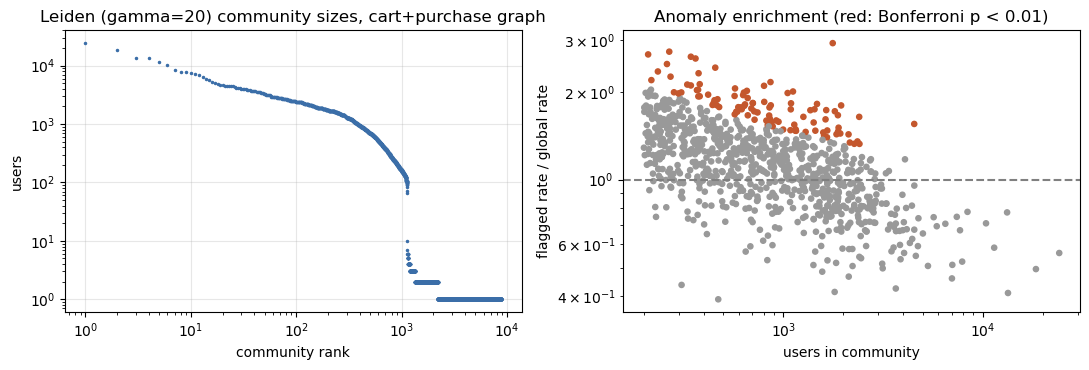

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sz = comm.users.sort_values(ascending=False).to_numpy()
ax[0].loglog(np.arange(1, len(sz) + 1), sz, ".", color="#3b6ea8", ms=3); ax[0].grid(alpha=.3)
ax[0].set_xlabel("community rank"); ax[0].set_ylabel("users"); ax[0].set_title(f"Leiden (gamma={GAMMA:g}) community sizes, cart+purchase graph")
ax[1].scatter(big.users, big.lift, s=14, c=np.where(big.p_bonf < 0.01, "#c4572d", "#999999"))
ax[1].axhline(1, ls="--", color="gray"); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("users in community"); ax[1].set_ylabel("flagged rate / global rate"); ax[1].set_title("Anomaly enrichment (red: Bonferroni p < 0.01)")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_6_2_communities.png", dpi=160); plt.show()

## 3. A drawable sub-graph: the most enriched mid-sized community
The most flagged-enriched significant community with 150 to 500 users. Users are drawn red (flagged by K-Means) or grey (not flagged); blue nodes are the 20 products reached by the most users of that community through cart/purchase edges. Node size of a product grows with the number of community users reaching it.

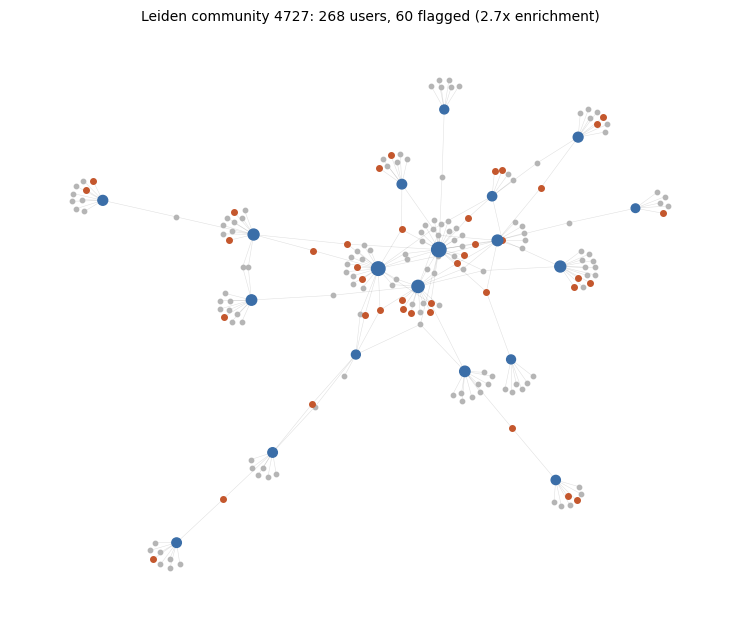

{'community': 4727, 'users': 268, 'flagged': 60, 'lift': 2.7435581089589274, 'nodes': 199, 'edges': 228, 'products': 19, 'users_drawn': 180, 'flagged_drawn': 40}


In [9]:
cand = top[(top.users >= 150) & (top.users <= 500) & (top.p_bonf < 0.01)]
cid = int(cand.index[0]); row = cand.iloc[0]
edges = q("""MATCH (u:User {leiden:$c})-[r:INTERACTED]->(p:Product) WHERE r.type IN ['cart','purchase']
    WITH p, collect(DISTINCT u) AS us WITH p, us, size(us) AS k ORDER BY k DESC LIMIT 20
    UNWIND us AS u RETURN u.userId AS u, u.flagged AS flagged, p.productId AS p, p.brand AS brand, k""", c=cid)
G = nx.Graph()
for e in edges:
    G.add_node(("u", e["u"]), kind="user", flagged=e["flagged"]); G.add_node(("p", e["p"]), kind="product", k=e["k"]); G.add_edge(("u", e["u"]), ("p", e["p"]))
G = G.subgraph(max(nx.connected_components(G), key=len)).copy()   # largest connected component only
users_n = [n for n in G if G.nodes[n]["kind"] == "user"]; prods_n = [n for n in G if G.nodes[n]["kind"] == "product"]
pos = nx.spring_layout(G, seed=5, k=0.5 / np.sqrt(len(G)) * 3, iterations=300)
fig, ax = plt.subplots(figsize=(7.5, 6.4))
nx.draw_networkx_edges(G, pos, alpha=.12, width=.4, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=[n for n in users_n if not G.nodes[n]["flagged"]], node_color="#b5b5b5", node_size=10, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=[n for n in users_n if G.nodes[n]["flagged"]], node_color="#c4572d", node_size=16, ax=ax)
nx.draw_networkx_nodes(G, pos, nodelist=prods_n, node_color="#3b6ea8", node_size=[20 + 3 * G.nodes[n]["k"] for n in prods_n], ax=ax)
ax.set_title(f"Leiden community {cid}: {int(row.users)} users, {int(row.flagged)} flagged ({row.lift:.1f}x enrichment)", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{FIG}/fig_6_3_suspicious_subgraph.png", dpi=160); plt.show()
metrics["subgraph"] = dict(community=cid, users=int(row.users), flagged=int(row.flagged), lift=float(row.lift),
                           nodes=G.number_of_nodes(), edges=G.number_of_edges(), products=len(prods_n),
                           users_drawn=len(users_n), flagged_drawn=sum(1 for n in users_n if G.nodes[n]["flagged"])); print(metrics["subgraph"]); save()

In [10]:
q("CALL gds.graph.drop('cp', false)"); save(); driver.close()

Received notification from DBMS server: <GqlStatusObject gql_status='01N03', status_description='warn: procedure field deprecated. The field `schema` of procedure gds.graph.drop() is deprecated.', position=<SummaryInputPosition line=1, column=1, offset=0>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 0, 'line': 1, 'column': 1}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "CALL gds.graph.drop('cp', false)"
